In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,  balanced_accuracy_score

from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, auc, average_precision_score

from sklearn.preprocessing import OneHotEncoder

import lightgbm as lgb
from lightgbm import LGBMClassifier

import tensorflow as tf
from tensorflow.keras import Sequential, layers
from tensorflow.keras import Model, layers, Input
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam


In [2]:
train_base = pd.read_csv('train_base.csv')
test_base  = pd.read_csv('test_base.csv')

train_base["Date"]=pd.to_datetime(train_base["Date"], format="%Y-%m-%d")
test_base["Date"]=pd.to_datetime(test_base["Date"], format="%Y-%m-%d")

train_base=train_base.sort_values("Date")
test_base=test_base.sort_values("Date")

X_train_raw = train_base.drop(columns=['RainTomorrow'], axis=1)
y_train = train_base['RainTomorrow']
X_test_raw = test_base.drop(columns=['RainTomorrow'], axis=1)
y_test = test_base['RainTomorrow']



X_val_raw = X_train_raw.iloc[-17391:]
X_train_raw = X_train_raw.iloc[:-17391]

y_val = y_train.iloc[-17391:]
y_train = y_train.iloc[:-17391]


cat_cols = X_train_raw.select_dtypes(include=["object"]).columns

enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_base_enc = enc.fit_transform(X_train_raw[cat_cols])
val_base_enc = enc.transform(X_val_raw[cat_cols])
test_base_enc= enc.transform(X_test_raw[cat_cols])


train_base_cat_df = pd.DataFrame(train_base_enc, columns=enc.get_feature_names_out(cat_cols), index=X_train_raw.index)
val_base_cat_df = pd.DataFrame(val_base_enc, columns=enc.get_feature_names_out(cat_cols), index=X_val_raw.index)
test_base_cat_df = pd.DataFrame(test_base_enc, columns=enc.get_feature_names_out(cat_cols), index=X_test_raw.index)


X_train = pd.concat([X_train_raw.drop(columns=cat_cols), train_base_cat_df], axis=1)
X_val = pd.concat([X_val_raw.drop(columns=cat_cols), val_base_cat_df], axis=1)
X_test = pd.concat([X_test_raw.drop(columns=cat_cols), test_base_cat_df], axis=1)

X_train = X_train.drop(columns=["Date"], axis=1)
X_val = X_val.drop(columns=["Date"], axis=1)
X_test = X_test.drop(columns=["Date"], axis=1)

y_train= y_train.replace({"Yes": 1, "No": 0})
y_test= y_test.replace({"Yes": 1, "No": 0})
y_val= y_val.replace({"Yes": 1, "No": 0})


n_train=75361
n_val=17391

**LightGBM Training - Baseline**

In [150]:
def score(probabilite, seuil):
    return (probabilite >= seuil).astype(int)


thresholds = np.arange(0, 1, 0.001)


model=LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            random_state=42,
            feature_fraction_seed=42,
            bagging_seed=42,
            data_random_seed=42,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
            n_jobs=1
        )


results_train=[]
results_val = []
results_test = []


model.fit(X_train, y_train)

############ Predictions and train ########################

prob_train = model.predict_proba(X_train)[:, 1]

#validation
aps = average_precision_score(y_train, prob_train)
roc = roc_auc_score(y_train, prob_train)

#Store validation results
results_train.append({
        'Train-AP': aps,
        'Train-ROC-AUC': roc,
})


############ Predictions and validation ########################

prob_val = model.predict_proba(X_val)[:, 1]

#validation
aps = average_precision_score(y_val, prob_val)
roc = roc_auc_score(y_val, prob_val)

    # Optimize threshold using validation data
scores = [
    f1_score(y_val, score(prob_val, t), zero_division=0)
    for t in thresholds
]

ix = np.argmax(scores)

final_thres = thresholds[ix]
f1 = scores[ix]

print("Optimal threshold: ", final_thres)

#Store validation results
results_val.append({
        'Val-AP': aps,
        'Val-ROC-AUC': roc,
        'Val-F1': f1,
        'Threshold': final_thres
})


############ Predictions and test ########################

prob_test = model.predict_proba(X_test)[:, 1]

# Apply validation threshold
preds_f1 = score(prob_test, final_thres)

# Metrics
aps = average_precision_score(y_test, prob_test)
roc = roc_auc_score(y_test, prob_test)
f1_score_test = f1_score(
    y_test,
    preds_f1,
    zero_division=0
)

# Store test results
results_test.append({
    'Test-AP': aps,
    'Test-ROC-AUC': roc,
    'Test-F1': f1_score_test,
    'Threshold': final_thres
})


# Display results as DataFrames

results_val_df = (
    pd.DataFrame(results_val)
    .sort_values(by='Val-AP', ascending=False)
)

results_test_df = (
    pd.DataFrame(results_test)
    .sort_values(by='Test-AP', ascending=False)
)

results_train_df = (
    pd.DataFrame(results_train)
    .sort_values(by='Train-AP', ascending=False)
)

print("\nTrain_results")
print(results_train_df)

print("\nVal_results")
print(results_val_df)

print("\nTest_results")
print(results_test_df)


Optimal threshold:  0.274

Train_results
   Train-AP  Train-ROC-AUC
0  0.784555       0.906266

Val_results
     Val-AP  Val-ROC-AUC    Val-F1  Threshold
0  0.706179     0.878967  0.637737      0.274

Test_results
   Test-AP  Test-ROC-AUC   Test-F1  Threshold
0  0.71741      0.873311  0.642594      0.274


**Feature Engineering -  Intra-Day Changes**

In [3]:
#Intra-day changes (afternoon minus morning on the same day)

X_train_a=X_train.copy()
X_val_a=X_val.copy()
X_test_a=X_test.copy()

X_train_a['Humidity_change_9to3'] = X_train['Humidity3pm'] - X_train['Humidity9am']
X_train_a['Temp_warming_9toMax']  = X_train['MaxTemp'] - X_train['Temp9am']

X_val_a['Humidity_change_9to3'] = X_val['Humidity3pm'] - X_val['Humidity9am']
X_val_a['Temp_warming_9toMax']  = X_val['MaxTemp'] - X_val['Temp9am']

X_test_a['Humidity_change_9to3'] = X_test['Humidity3pm'] - X_test['Humidity9am']
X_test_a['Temp_warming_9toMax']  = X_test['MaxTemp'] - X_test['Temp9am']

intraday_cols=['Humidity_change_9to3', 'Temp_warming_9toMax']


**Feature Engineering -  24-Hour Change**

In [4]:
# Average daily values per region so .shift(1) steps by 1 calendar day

daily_cols = ['Humidity3pm', 'Pressure3pm', 'WindGustSpeed', 'Rainfall', 'Cloud9am']

train_24 = X_train_raw.copy()
val_24   = X_val_raw.copy()
test_24  = X_test_raw.copy()

############## train ####################################
daily = train_24.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_24h']   = (daily['Humidity3pm']   - reg['Humidity3pm'].shift(1)).fillna(0)
daily['Pressure3pm_24h']   = (daily['Pressure3pm']   - reg['Pressure3pm'].shift(1)).fillna(0)
daily['WindGustSpeed_24h'] = (daily['WindGustSpeed'] - reg['WindGustSpeed'].shift(1)).fillna(0)

diff_cols = ['Humidity3pm_24h','Pressure3pm_24h','WindGustSpeed_24h']

train_24 = train_24.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

train_24=train_24.drop("Date", axis=1)

############## validate ####################################

daily = val_24.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_24h']   = (daily['Humidity3pm']   - reg['Humidity3pm'].shift(1)).fillna(0)
daily['Pressure3pm_24h']   = (daily['Pressure3pm']   - reg['Pressure3pm'].shift(1)).fillna(0)
daily['WindGustSpeed_24h'] = (daily['WindGustSpeed'] - reg['WindGustSpeed'].shift(1)).fillna(0)

diff_cols = ['Humidity3pm_24h','Pressure3pm_24h','WindGustSpeed_24h']

val_24 = val_24.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

val_24=val_24.drop("Date", axis=1)

############## test ####################################

daily = test_24.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_24h']   = (daily['Humidity3pm']   - reg['Humidity3pm'].shift(1)).fillna(0)
daily['Pressure3pm_24h']   = (daily['Pressure3pm']   - reg['Pressure3pm'].shift(1)).fillna(0)
daily['WindGustSpeed_24h'] = (daily['WindGustSpeed'] - reg['WindGustSpeed'].shift(1)).fillna(0)

diff_cols = ['Humidity3pm_24h','Pressure3pm_24h','WindGustSpeed_24h']

test_24 = test_24.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

test_24=test_24.drop("Date", axis=1)

############## Concat ####################################

cat_cols = train_24.select_dtypes(include=["object"]).columns

enc = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_24_enc = enc.fit_transform(train_24[cat_cols])
val_24_enc = enc.transform(val_24[cat_cols])
test_24_enc= enc.transform(test_24[cat_cols])


train_base_cat_df = pd.DataFrame(train_24_enc, columns=enc.get_feature_names_out(cat_cols), index=train_24.index)
val_base_cat_df = pd.DataFrame(val_24_enc, columns=enc.get_feature_names_out(cat_cols), index=val_24.index)
test_base_cat_df = pd.DataFrame(test_24_enc, columns=enc.get_feature_names_out(cat_cols), index=test_24.index)

X_train_24 = train_24.drop(columns=cat_cols, axis=1)
X_val_24 = val_24.drop(columns=cat_cols, axis=1)
X_test_24 = test_24.drop(columns=cat_cols, axis=1)

X_train_b = pd.concat([X_train_24, train_base_cat_df], axis=1)
X_val_b = pd.concat([X_val_24, val_base_cat_df], axis=1)
X_test_b = pd.concat([X_test_24, test_base_cat_df], axis=1)

X_train_b['Humidity_change_9to3'] = (X_train_a['Humidity_change_9to3'].to_numpy())
X_val_b['Humidity_change_9to3'] = (X_val_a['Humidity_change_9to3'].to_numpy())
X_test_b['Humidity_change_9to3'] = (X_test_a['Humidity_change_9to3'].to_numpy())

X_train_b['Temp_warming_9toMax'] = (X_train_a['Temp_warming_9toMax'].to_numpy())
X_val_b['Temp_warming_9toMax'] = (X_val_a['Temp_warming_9toMax'].to_numpy())
X_test_b['Temp_warming_9toMax'] = (X_test_a['Temp_warming_9toMax'].to_numpy())



shift24_cols = ['Humidity3pm_24h', 'Pressure3pm_24h', 'WindGustSpeed_24h']


**Feature Engineering -  3-Day Moving Average**

In [5]:
# 3-day rolling averages (.rolling(3))
train_3 = X_train_raw.copy()
val_3   = X_val_raw.copy()
test_3  = X_test_raw.copy()

############## train ####################################
daily = train_3.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_3d']   = reg['Humidity3pm'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Pressure3pm_3d']   = reg['Pressure3pm'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['WindGustSpeed_3d'] = reg['WindGustSpeed'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Rainfall_3d']      = reg['Rainfall'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Cloud9am_3d']      = reg['Cloud9am'].transform(lambda s: s.rolling(3, min_periods=1).mean())

diff_cols= ['Humidity3pm_3d', 'Pressure3pm_3d', 'WindGustSpeed_3d', 'Rainfall_3d', 'Cloud9am_3d']

train_3 = train_3.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

train_3=train_3.drop(["Date","Location","RainToday"], axis=1)
train_3=train_3[diff_cols]
############## validate ####################################

daily = val_3.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_3d']   = reg['Humidity3pm'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Pressure3pm_3d']   = reg['Pressure3pm'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['WindGustSpeed_3d'] = reg['WindGustSpeed'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Rainfall_3d']      = reg['Rainfall'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Cloud9am_3d']      = reg['Cloud9am'].transform(lambda s: s.rolling(3, min_periods=1).mean())

diff_cols= ['Humidity3pm_3d', 'Pressure3pm_3d', 'WindGustSpeed_3d', 'Rainfall_3d', 'Cloud9am_3d']

val_3 = val_3.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

val_3=val_3.drop(["Date","Location","RainToday"], axis=1)
val_3=val_3[diff_cols]
############## test ####################################

daily = test_3.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_3d']   = reg['Humidity3pm'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Pressure3pm_3d']   = reg['Pressure3pm'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['WindGustSpeed_3d'] = reg['WindGustSpeed'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Rainfall_3d']      = reg['Rainfall'].transform(lambda s: s.rolling(3, min_periods=1).mean())
daily['Cloud9am_3d']      = reg['Cloud9am'].transform(lambda s: s.rolling(3, min_periods=1).mean())

diff_cols= ['Humidity3pm_3d', 'Pressure3pm_3d', 'WindGustSpeed_3d', 'Rainfall_3d', 'Cloud9am_3d']

test_3 = test_3.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

test_3=test_3.drop(["Date","Location","RainToday"], axis=1)
test_3=test_3[diff_cols]
 
######### final concat ################

X_train_c=pd.concat([train_3, X_train_b], axis=1)
X_val_c=pd.concat([val_3, X_val_b], axis=1)
X_test_c=pd.concat([test_3, X_test_b], axis=1)


roll3_cols = ['Humidity3pm_3d', 'Pressure3pm_3d', 'WindGustSpeed_3d', 'Rainfall_3d', 'Cloud9am_3d']


**Feature Engineering -  7-Day Moving Average**

In [6]:
#7-day rolling averages (.rolling(7))
train_7 = X_train_raw.copy()
val_7   = X_val_raw.copy()
test_7  = X_test_raw.copy()

############## train ####################################
daily = train_7.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_7d']   = reg['Humidity3pm'].transform(lambda s: s.rolling(7, min_periods=1).mean())
daily['Pressure3pm_7d']   = reg['Pressure3pm'].transform(lambda s: s.rolling(7, min_periods=1).mean())
daily['Rainfall_7d']      = reg['Rainfall'].transform(lambda s: s.rolling(7, min_periods=1).mean())

diff_cols= ['Humidity3pm_7d', 'Pressure3pm_7d', 'Rainfall_7d']

train_7 = train_7.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

train_7=train_7.drop(["Date","Location","RainToday"], axis=1)
train_7=train_7[diff_cols]

############## validate ####################################

daily = val_7.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_7d']   = reg['Humidity3pm'].transform(lambda s: s.rolling(7, min_periods=1).mean())
daily['Pressure3pm_7d']   = reg['Pressure3pm'].transform(lambda s: s.rolling(7, min_periods=1).mean())
daily['Rainfall_7d']      = reg['Rainfall'].transform(lambda s: s.rolling(7, min_periods=1).mean())

diff_cols= ['Humidity3pm_7d', 'Pressure3pm_7d', 'Rainfall_7d']

val_7 = val_7.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

val_7=val_7.drop(["Date","Location","RainToday"], axis=1)
val_7=val_7[diff_cols]

############## test ####################################

daily = test_7.groupby(['Location', 'Date'], as_index=False)[daily_cols].mean()
reg   = daily.groupby('Location')

daily['Humidity3pm_7d']   = reg['Humidity3pm'].transform(lambda s: s.rolling(7, min_periods=1).mean())
daily['Pressure3pm_7d']   = reg['Pressure3pm'].transform(lambda s: s.rolling(7, min_periods=1).mean())
daily['Rainfall_7d']      = reg['Rainfall'].transform(lambda s: s.rolling(7, min_periods=1).mean())

diff_cols= ['Humidity3pm_7d', 'Pressure3pm_7d', 'Rainfall_7d']

test_7 = test_7.merge(daily[['Location', 'Date'] + diff_cols],on=['Location', 'Date'],how='left')

test_7=test_7.drop(["Date","Location","RainToday"], axis=1)
test_7=test_7[diff_cols]
 
######### final concat ################

X_train_d=pd.concat([train_7, X_train_c], axis=1)
X_val_d=pd.concat([val_7, X_val_c], axis=1)
X_test_d=pd.concat([test_7, X_test_c], axis=1)


roll7_cols = ['Humidity3pm_7d', 'Pressure3pm_7d', 'Rainfall_7d']


**Some testing after feature engineering**

In [7]:
print(len(X_train_c), len(y_train))
print(len(X_val_c), len(y_val))
print(len(X_test_c), len(y_test))

print(X_train_c.shape)
print(X_val_c.shape)
print(X_test_c.shape)

75361 75361
17391 17391
23188 23188
(75361, 40)
(17391, 40)
(23188, 40)


In [8]:
X_train_a.index = X_train_raw.index
X_val_a.index = X_val_raw.index
X_test_a.index = X_test_raw.index

X_train_b.index = X_train_raw.index
X_val_b.index = X_val_raw.index
X_test_b.index = X_test_raw.index

X_train_c.index = X_train_raw.index
X_val_c.index = X_val_raw.index
X_test_c.index = X_test_raw.index

X_train_d.index = X_train_raw.index
X_val_d.index = X_val_raw.index
X_test_d.index = X_test_raw.index

In [9]:
assert list(X_train_a.columns) == list(X_val_a.columns)
assert list(X_train_a.columns) == list(X_test_a.columns)

assert X_train_a.index.equals(y_train.index)
assert X_val_a.index.equals(y_val.index)
assert X_test_a.index.equals(y_test.index)

print("Set a: All checks passed!")


assert list(X_train_b.columns) == list(X_val_b.columns)
assert list(X_train_b.columns) == list(X_test_b.columns)

assert X_train_b.index.equals(y_train.index)
assert X_val_b.index.equals(y_val.index)
assert X_test_b.index.equals(y_test.index)

print("Set b: All checks passed!")


assert list(X_train_c.columns) == list(X_val_c.columns)
assert list(X_train_c.columns) == list(X_test_c.columns)

assert X_train_c.index.equals(y_train.index)
assert X_val_c.index.equals(y_val.index)
assert X_test_c.index.equals(y_test.index)

print("Set c: All checks passed!")


assert list(X_train_d.columns) == list(X_val_d.columns)
assert list(X_train_d.columns) == list(X_test_d.columns)

assert X_train_d.index.equals(y_train.index)
assert X_val_d.index.equals(y_val.index)
assert X_test_d.index.equals(y_test.index)

print("Set d: All checks passed!")

Set a: All checks passed!
Set b: All checks passed!
Set c: All checks passed!
Set d: All checks passed!


In [10]:
print(X_train_raw[['Location', 'Date']].head())
print(train_base.loc[y_train.index, ['Location', 'Date']].head())

          Location       Date
0  Canberra Region 2007-11-01
1  Canberra Region 2007-11-02
2  Canberra Region 2007-11-03
3  Canberra Region 2007-11-04
4  Canberra Region 2007-11-05
          Location       Date
0  Canberra Region 2007-11-01
1  Canberra Region 2007-11-02
2  Canberra Region 2007-11-03
3  Canberra Region 2007-11-04
4  Canberra Region 2007-11-05


In [11]:
pd.testing.assert_frame_equal(
    X_train_raw[['Location', 'Date']].reset_index(drop=True),
    train_base.loc[y_train.index, ['Location', 'Date']].reset_index(drop=True)
)

In [12]:
for name, X in {
    "a": X_train_a,
    "b": X_train_b,
    "c": X_train_c,
    "d": X_train_d
}.items():

    pd.testing.assert_frame_equal(
        X[['Location', 'Date']].reset_index(drop=True)
        if 'Location' in X.columns else
        X_train_raw[['Location', 'Date']].reset_index(drop=True),

        X_train_raw[['Location', 'Date']].reset_index(drop=True)
    )

print("All feature sets have the correct row order!")

All feature sets have the correct row order!


**SHAP Analysis with engineered features**

In [161]:
# Train LightGBM on the combined features and compute SHAP values
base_cols=list(X_train.columns)

def score(probabilite, seuil):
    return (probabilite >= seuil).astype(int)


thresholds = np.arange(0, 1, 0.001)

lgb_base = LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            random_state=42,
            feature_fraction_seed=42,
            bagging_seed=42,
            data_random_seed=42,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
            n_jobs=1
        )
lgb_base.fit(X_train, y_train)

#validation
prob_val = lgb_base.predict_proba(X_val)[:, 1]


print("APS-Val: ", average_precision_score(y_val, prob_val))

#SHAP

shap_matrix_base = lgb_base.predict(X_val, pred_contrib=True)[:, :-1]
shap_base = pd.Series(
    np.abs(shap_matrix_base).mean(axis=0),
    index=base_cols
).sort_values(ascending=False)

# Plot Top 10 Baseline SHAP Summary Graph (left) and Bar Diagram (right)
top10_cols = shap_base.head(10).index[::-1].tolist()
top10_idx  = [base_cols.index(c) for c in top10_cols]

rng = np.random.default_rng(42)
sample_rows = rng.choice(len(X_val), size=2000, replace=False)

########################################################################################################

lgb_comb=LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            random_state=42,
            feature_fraction_seed=42,
            bagging_seed=42,
            data_random_seed=42,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
            n_jobs=1
        )
lgb_comb.fit(X_train_d, y_train)

results_train=[]
results_val = []
results_test = []

############ Predictions and train ########################

prob_train = lgb_comb.predict_proba(X_train_d)[:, 1]

#validation
aps = average_precision_score(y_train, prob_train)
roc = roc_auc_score(y_train, prob_train)

#Store validation results
results_train.append({
        'Train-AP': aps,
        'Train-ROC-AUC': roc,
})


############ Predictions and validation ########################

prob_val = lgb_comb.predict_proba(X_val_d)[:, 1]

#validation
aps = average_precision_score(y_val, prob_val)
roc = roc_auc_score(y_val, prob_val)

    # Optimize threshold using validation data
scores = [
    f1_score(y_val, score(prob_val, t), zero_division=0)
    for t in thresholds
]

ix = np.argmax(scores)

final_thres = thresholds[ix]
f1 = scores[ix]

print("Optimal threshold: ", final_thres)

#Store validation results
results_val.append({
        'Val-AP': aps,
        'Val-ROC-AUC': roc,
        'Val-F1': f1,
        'Threshold': final_thres
})


############ Predictions and test ########################

prob_test = lgb_comb.predict_proba(X_test_d)[:, 1]

# Apply validation threshold
preds_f1 = score(prob_test, final_thres)

# Metrics
aps = average_precision_score(y_test, prob_test)
roc = roc_auc_score(y_test, prob_test)
f1_score_test = f1_score(
    y_test,
    preds_f1,
    zero_division=0
)

# Store test results
results_test.append({
    'Test-AP': aps,
    'Test-ROC-AUC': roc,
    'Test-F1': f1_score_test,
    'Threshold': final_thres
})


# Display results as DataFrames

results_val_df = (
    pd.DataFrame(results_val)
    .sort_values(by='Val-AP', ascending=False)
)

results_test_df = (
    pd.DataFrame(results_test)
    .sort_values(by='Test-AP', ascending=False)
)

results_train_df = (
    pd.DataFrame(results_train)
    .sort_values(by='Train-AP', ascending=False)
)

print("\nTrain_results")
print(results_train_df)

print("\nVal_results")
print(results_val_df)

print("\nTest_results")
print(results_test_df)


APS-Val:  0.706178689377311
Optimal threshold:  0.28

Train_results
   Train-AP  Train-ROC-AUC
0   0.81017        0.92123

Val_results
     Val-AP  Val-ROC-AUC   Val-F1  Threshold
0  0.713028     0.884384  0.64626       0.28

Test_results
    Test-AP  Test-ROC-AUC   Test-F1  Threshold
0  0.727113      0.878908  0.652114       0.28


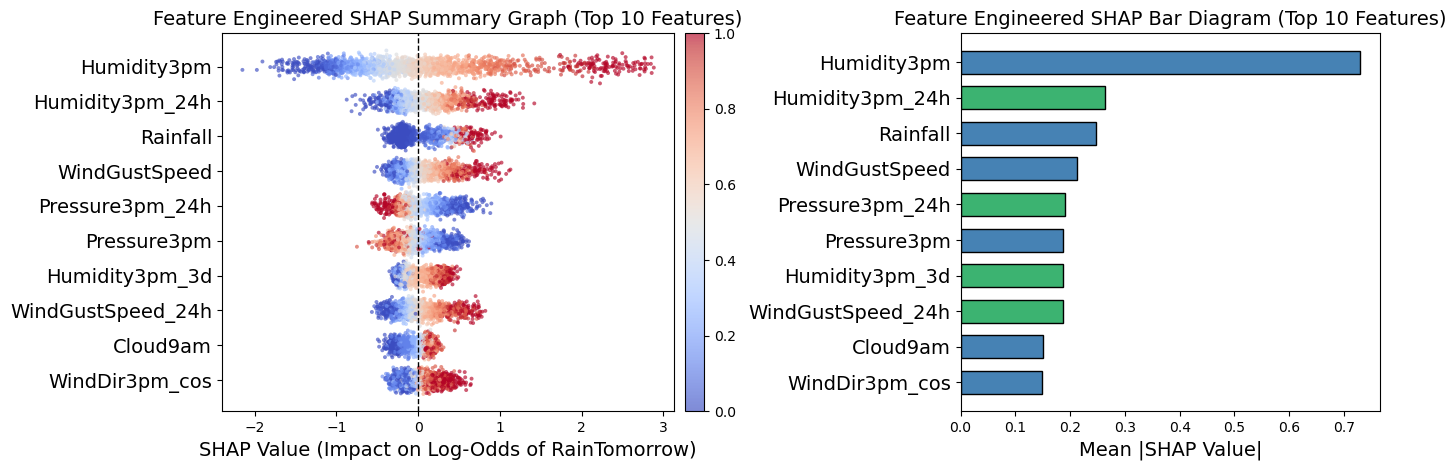

In [162]:
################################   SHAP   ####################################################

combined_cols=list(X_train_d.columns)
engineered_cols=intraday_cols + shift24_cols + roll3_cols + roll7_cols

# Calculate TreeSHAP values for Combined Model
shap_matrix_comb = lgb_comb.predict(
    X_val_d[combined_cols],
    pred_contrib=True
)[:, :-1]

shap_comb = pd.Series(
    np.abs(shap_matrix_comb).mean(axis=0),
    index=combined_cols
).sort_values(ascending=False)


# Select Top 12 Combined Features
top10_c_cols = shap_comb.head(10).index[::-1].tolist()
top10_c_idx  = [combined_cols.index(c) for c in top10_c_cols]


# Reproducible random sample
rng = np.random.default_rng(42)
sample_rows = rng.choice(len(X_val_d),size=min(2000, len(X_val_d)), replace=False)


# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.3, 1.0]})


# 1. LEFT: SHAP Beeswarm Summary Graph
for pos, col_idx in enumerate(top10_c_idx):

    sv = shap_matrix_comb[sample_rows, col_idx]

    fv = X_val_d[combined_cols].iloc[sample_rows, col_idx].values

    fv_norm = np.clip((fv - np.percentile(fv, 5)) / (np.percentile(fv, 95) - np.percentile(fv, 5) + 1e-9), 0, 1)

    y_jitter = pos + rng.normal(0, 0.13, size=len(sv))

    sc = axes[0].scatter(sv, y_jitter, c=fv_norm, cmap='coolwarm', s=8, alpha=0.65, edgecolors='none')


axes[0].axvline(0, color='black', linestyle='--', lw=1)
axes[0].set_yticks(range(len(top10_c_cols)))
axes[0].set_yticklabels(top10_c_cols, fontsize=14)
axes[0].set_xlabel('SHAP Value (Impact on Log-Odds of RainTomorrow)', fontsize=14)
axes[0].set_title('Feature Engineered SHAP Summary Graph (Top 10 Features)', fontsize=14)
plt.colorbar(sc, ax=axes[0], pad=0.02)


# 2. RIGHT: SHAP Bar Diagram
colors_comb = [
    'mediumseagreen' if f in engineered_cols
    else 'steelblue'
    for f in top10_c_cols
]

axes[1].barh(top10_c_cols, [shap_comb[c] for c in top10_c_cols], color=colors_comb, edgecolor='black', height=0.65)
axes[1].tick_params(axis='y', labelsize=14)
axes[1].set_xlabel('Mean |SHAP Value|', fontsize=14)
axes[1].set_title('Feature Engineered SHAP Bar Diagram (Top 10 Features)', fontsize=14)


plt.tight_layout()
plt.show()


**Step-by-Step Model Performance**

In [163]:
thresholds_grid = np.linspace(0.15, 0.65, 101)

def evaluate_lgbm_step(step_name, X_train, X_val, X_test, y_train, y_val, y_test):
    model=LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            random_state=42,
            feature_fraction_seed=42,
            bagging_seed=42,
            data_random_seed=42,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
            n_jobs=1
        )
    model.fit(X_train, y_train)
   
    p_train   = model.predict_proba(X_train)[:, 1]
    p_val     = model.predict_proba(X_val)[:, 1]
    p_test    = model.predict_proba(X_test)[:, 1]

    # Find probability threshold t* that maximizes F1 on the Validation set
    val_f1_scores = [f1_score(y_val, (p_val >= t).astype(int)) for t in thresholds_grid]
    best_t = thresholds_grid[int(np.argmax(val_f1_scores))]
    pred_test_05 = (p_test >= 0.50).astype(int)
    pred_test_opt = (p_test >= best_t).astype(int)
    
    return {
        'Step': step_name,
        'Features': X_train.shape[1],
        'Train_AP': round(average_precision_score(y_train, p_train), 4),
        'Val_AP': round(average_precision_score(y_val, p_val), 4),
        'ROC_AUC_AP': round(roc_auc_score(y_val, p_val), 4),
        'Test_AP': round(average_precision_score(y_test, p_test), 4),
        'Test_ROC_AUC': round(roc_auc_score(y_test, p_test), 4),
        'Best_Val_t*': round(best_t, 3),
        'Test_F1 (t=0.50)': round(f1_score(y_test, pred_test_05), 4),
        'Test_F1 (t=t*)': round(f1_score(y_test, pred_test_opt), 4),
        'Test_Bal_Acc (t=0.50)': round(balanced_accuracy_score(y_test, pred_test_05), 4),
        'Test_Bal_Acc (t=t*)': round(balanced_accuracy_score(y_test, pred_test_opt), 4)
    }

steps_list = [
    ('1. Baseline Model', X_train, X_val, X_test),
    ('2. + Intra-Day Changes', X_train_a, X_val_a, X_test_a),
    ('3. + 24h .shift(1) Changes', X_train_b, X_val_b, X_test_b),
    ('4. + 3-Day .rolling(3)', X_train_c, X_val_c, X_test_c),
    ('5. + 7-Day .rolling(7)', X_train_d, X_val_d, X_test_d)]

step_comparison_df = pd.DataFrame([
    evaluate_lgbm_step(name, X_tr, X_va, X_te, y_train, y_val, y_test) for name, X_tr, X_va, X_te in steps_list])

step_comparison_df


,Step,Features,Train_AP,Val_AP,ROC_AUC_AP,Test_AP,Test_ROC_AUC,Best_Val_t*,Test_F1 (t=0.50),Test_F1 (t=t*),Test_Bal_Acc (t=0.50),Test_Bal_Acc (t=t*)
0,1. Baseline Model,30,0.7846,0.7062,0.8790,0.7174,0.8733,0.275,0.6189,0.6429,0.7404,0.7849
1,2. + Intra-Day Changes,32,0.7868,0.7061,0.8791,0.7201,0.8740,0.280,0.6178,0.6441,0.7398,0.7855
2,3. + 24h .shift(1) Changes,35,0.8012,0.7148,0.8858,0.7299,0.8791,0.255,0.6267,0.6497,0.7451,0.7938
3,4. + 3-Day .rolling(3),40,0.8083,0.7173,0.8861,0.7273,0.8789,0.305,0.6258,0.6556,0.7446,0.7878
4,5. + 7-Day .rolling(7),43,0.8102,0.7130,0.8844,0.7271,0.8789,0.280,0.6252,0.6521,0.7439,0.7903


C:\Users\Irmigeheuer\AppData\Local\Temp\ipykernel_7764\1814121984.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gen_gap["Gap"]=gen_gap["Train_AP"]-gen_gap["Val_AP"]


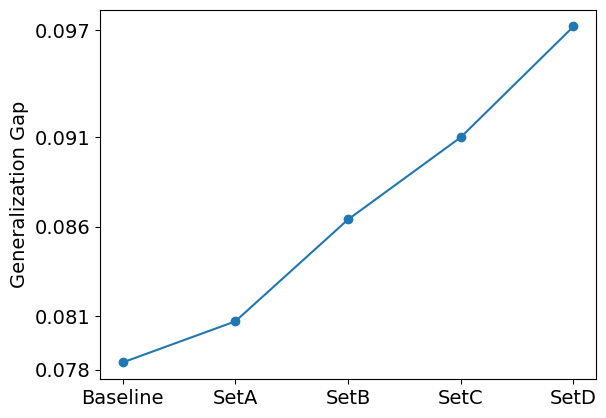

In [164]:
gen_gap=step_comparison_df[["Train_AP","Val_AP"]]
gen_gap["Gap"]=gen_gap["Train_AP"]-gen_gap["Val_AP"]


plt.plot([1,2,3,4,5], gen_gap["Gap"], marker="o")
plt.xticks(ticks=[1,2,3,4,5], labels=["Baseline", "SetA", "SetB", "SetC", "SetD"], fontsize=14)
plt.yticks(ticks=round(gen_gap["Gap"],3), fontsize=14)
plt.ylabel("Generalization Gap", fontsize=14);

In [165]:
gen_gap["Gap"]

0    0.0784
1    0.0807
2    0.0864
3    0.0910
4    0.0972
Name: Gap, dtype: float64

**Detailed Region-Wise Scores Across All 16 Climate Regions**

In [166]:
train_all = pd.read_csv('train_base.csv')
test_all  = pd.read_csv('test_base.csv')

train_all["Date"]=pd.to_datetime(train_all["Date"], format="%Y-%m-%d")
test_all["Date"]=pd.to_datetime(test_all["Date"], format="%Y-%m-%d")

train_all=train_all.sort_values("Date")
test_all=test_all.sort_values("Date")

val_all = train_all.iloc[-17391:]
train_all = train_all.iloc[:-17391]


#####################################################################
lgb_final = LGBMClassifier(
            objective='binary',
            boosting_type='gbdt',
            random_state=42,
            feature_fraction_seed=42,
            bagging_seed=42,
            data_random_seed=42,
            deterministic=True,
            force_col_wise=True,
            verbosity=-1,
            n_jobs=1
        )
lgb_final.fit(X_train_b, y_train)

p_val_final  = lgb_final.predict_proba(X_val_b)[:, 1]
p_test_final = lgb_final.predict_proba(X_test_b)[:, 1]

val_f1_curve = [f1_score(y_val, (p_val_final >= t).astype(int)) for t in thresholds_grid]
ultimate_t   = round(float(thresholds_grid[int(np.argmax(val_f1_curve))]), 3)

# Compute region-wise Validation and Test scores for Baseline vs Final Combined model (at t=0.50 and ultimate t*)
p_val_base   = lgb_base.predict_proba(X_val)[:, 1]
p_test_base  = lgb_base.predict_proba(X_test)[:, 1]
pred_base    = lgb_base.predict(X_test)
pred_final   = lgb_final.predict(X_test_b)
pred_fin_opt = (p_test_final >= ultimate_t).astype(int)

f1_opt_col = f'Final_F1 (t*={ultimate_t:.3f})'
region_rows = []
for region in sorted(test_all['Location'].unique()):
    val_mask  = (val_all['Location'].values == region)
    test_mask = (test_all['Location'].values == region)
    y_reg_val  = y_val.values[val_mask]
    y_reg_test = y_test.values[test_mask]
    
    val_ap_base  = average_precision_score(y_reg_val, p_val_base[val_mask])
    val_ap_final = average_precision_score(y_reg_val, p_val_final[val_mask])
    ap_base      = average_precision_score(y_reg_test, p_test_base[test_mask])
    ap_final     = average_precision_score(y_reg_test, p_test_final[test_mask])
    f1_base      = f1_score(y_reg_test, pred_base[test_mask])
    f1_final     = f1_score(y_reg_test, pred_final[test_mask])
    f1_opt       = f1_score(y_reg_test, pred_fin_opt[test_mask])
    auc_fin      = roc_auc_score(y_reg_test, p_test_final[test_mask])
    
    region_rows.append({
        'Region': region,
        'Test_Rows': int(test_mask.sum()),
        'Rain_Rate_%': round(100 * y_reg_test.mean(), 2),
        'Val_Baseline_AP': round(val_ap_base, 4),
        'Val_Final_AP': round(val_ap_final, 4),
        'Val_AP_Gain': round(val_ap_final - val_ap_base, 4),
        'Baseline_AP': round(ap_base, 4),
        'Final_AP': round(ap_final, 4),
        'AP_Gain': round(ap_final - ap_base, 4),
        'Baseline_F1 (t=0.50)': round(f1_base, 4),
        'Final_F1 (t=0.50)': round(f1_final, 4),
        f1_opt_col: round(f1_opt, 4),
        'Final_ROC_AUC': round(auc_fin, 4)
    })

region_df = pd.DataFrame(region_rows).sort_values('Final_AP', ascending=False).reset_index(drop=True)
region_df

,Region,Test_Rows,Rain_Rate_%,Val_Baseline_AP,Val_Final_AP,Val_AP_Gain,Baseline_AP,Final_AP,AP_Gain,Baseline_F1 (t=0.50),Final_F1 (t=0.50),Final_F1 (t*=0.255),Final_ROC_AUC
0,Southwest Victoria,1773,31.42,0.7711,0.7804,0.0093,0.8237,0.8284,0.0048,0.7096,0.7078,0.7264,0.8955
1,Perth Region,1778,18.73,0.8194,0.8261,0.0067,0.7619,0.7714,0.0095,0.6864,0.6866,0.7102,0.9182
2,Victoria Inland East,1184,22.38,0.6325,0.6419,0.0094,0.7295,0.7480,0.0185,0.6392,0.6789,0.6774,0.8927
3,South Australia,1180,14.15,0.6103,0.6004,-0.0100,0.7242,0.7430,0.0188,0.6523,0.6406,0.6831,0.9209
4,Canberra Region,1778,22.78,0.6334,0.6658,0.0325,0.7008,0.7340,0.0332,0.6041,0.6124,0.6208,0.8685
5,Top End NT,1170,26.84,0.7517,0.7404,-0.0114,0.7389,0.7316,-0.0072,0.6422,0.6474,0.6597,0.8672
6,Norfolk Island,552,34.96,0.6747,0.6858,0.0111,0.7346,0.7315,-0.0031,0.6310,0.6393,0.6488,0.8098
7,Southwest Western Australia,2299,27.58,0.7243,0.7323,0.0080,0.7234,0.7302,0.0068,0.6077,0.6021,0.6597,0.8502
8,Sydney Region,3530,22.01,0.7170,0.7388,0.0219,0.6950,0.7202,0.0253,0.6051,0.6184,0.6268,0.8657
9,North Queensland,1138,26.45,0.6984,0.6871,-0.0113,0.7002,0.7001,-0.0001,0.5660,0.5898,0.6319,0.8432


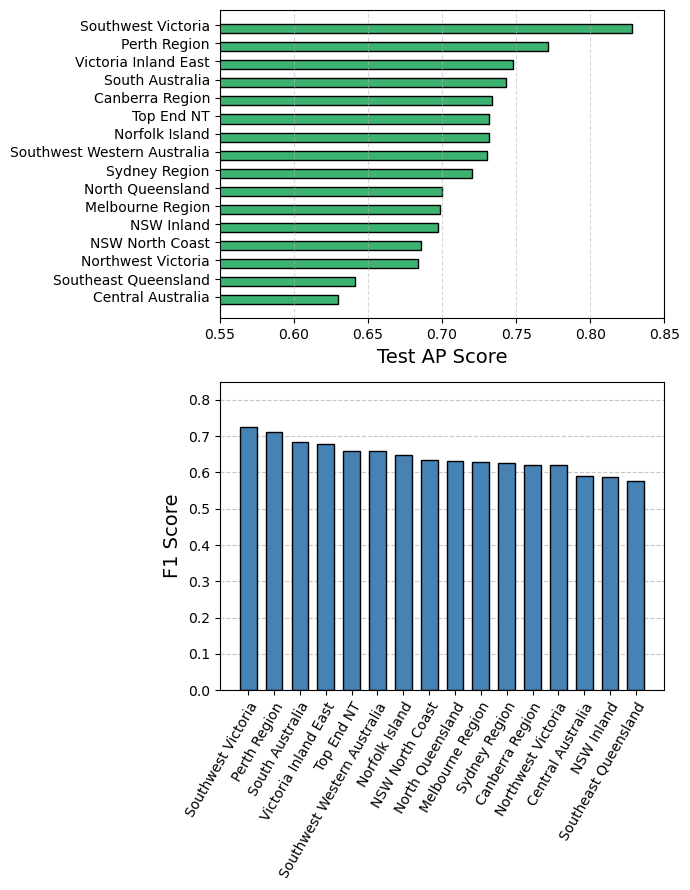

In [167]:
# Grouped Bar Diagrams comparing Region-Wise Baseline vs Final AP and F1 Scores
y_pos = np.arange(len(region_df))
fig, axes = plt.subplots(2, 1, figsize=(7,9))


# Sort regions by Final AP score (descending)
region_df_sorted_ap = region_df.sort_values(by='Final_AP', ascending=False).reset_index(drop=True)

y_pos_sorted_ap = np.arange(len(region_df_sorted_ap))

axes[0].barh(y_pos_sorted_ap + 0.18, region_df_sorted_ap['Final_AP'], height=0.5, color='mediumseagreen', edgecolor='black')
axes[0].set_yticks(y_pos_sorted_ap)
axes[0].set_yticklabels(region_df_sorted_ap['Region'],fontsize=10)
axes[0].invert_yaxis()
axes[0].set_xlim(0.55, 0.85)
axes[0].set_xlabel('Test AP Score', fontsize=14)
axes[0].tick_params(axis='y', labelsize=10)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)


# Sort regions by optimized F1 score (descending)
region_df_sorted_f1 = region_df.sort_values(by=f1_opt_col, ascending=False).reset_index(drop=True)

y_pos_sorted_f1 = np.arange(len(region_df_sorted_f1))

axes[1].bar(y_pos_sorted, region_df_sorted[f1_opt_col], width=0.65, color='steelblue', edgecolor='black')
axes[1].set_xticks(y_pos_sorted)
axes[1].set_xticklabels(region_df_sorted['Region'], rotation=60, ha='right', rotation_mode='anchor', fontsize=10)
axes[1].set_ylabel('F1 Score', fontsize=14)
#axes[1].set_title(f'Region-Wise Final F1 Score (t*={ultimate_t:.3f})',fontsize=12)
axes[1].set_ylim(0, 0.85)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
axes[1].set_axisbelow(True)

# More space for rotated labels
plt.subplots_adjust(hspace=0.6, bottom=0.25)
plt.tight_layout()
plt.show();

     

**Neural Network**

In [13]:
################### APS calculation #####################################
class APSCallback(tf.keras.callbacks.Callback):
    def __init__(self, X_train, y_train, X_val, y_val):
        super().__init__()
        self.X_train = X_train
        self.y_train = y_train
        self.X_val = X_val
        self.y_val = y_val

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        # Train AP
        proba_train = self.model.predict(self.X_train, verbose=0).ravel()
        aps_train = average_precision_score(self.y_train, proba_train)

        # Validation AP
        proba_val = self.model.predict(self.X_val, verbose=0).ravel()
        aps_val = average_precision_score(self.y_val, proba_val)

        logs["train_aps"] = aps_train
        logs["val_aps"] = aps_val

        print(f" - train_aps: {aps_train:.4f} - val_aps: {aps_val:.4f}")

aps_cb = APSCallback(
    X_train_b, y_train,
    X_val_b, y_val
)


######### Neural Network ###############################
inputs = Input(shape=(X_train_b.shape[1],))

x = layers.Dense(64, activation='relu')(inputs)
x = layers.Dropout(0.2)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)

outputs = layers.Dense(1, activation='sigmoid')(x)

model = Model(inputs=inputs, outputs=outputs)


model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_aps", mode="max", patience=15, restore_best_weights=True
)

history = model.fit(
    X_train_b, y_train,
    validation_data=(X_val_b, y_val),
    batch_size=32,
    epochs=35,
    callbacks=[aps_cb, early_stop],
    verbose=1
)



Epoch 1/35
2350/2356 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7507 - auc: 0.7252 - loss: 0.4974 - precision: 0.4980 - recall: 0.3720 - train_aps: 0.7073 - val_aps: 0.6630
2356/2356 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - accuracy: 0.7509 - auc: 0.7254 - loss: 0.4972 - precision: 0.4984 - recall: 0.3722 - val_accuracy: 0.8485 - val_auc: 0.8581 - val_loss: 0.3517 - val_precision: 0.6879 - val_recall: 0.4875 - train_aps: 0.7073 - val_aps: 0.6630
Epoch 2/35
2348/2356 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8441 - auc: 0.8571 - loss: 0.3673 - precision: 0.7136 - recall: 0.5182 - train_aps: 0.7190 - val_aps: 0.6765
2356/2356 ━━━━━━━━━━━━━━━━━━━━ 16s 7ms/step - accuracy: 0.8441 - auc: 0.8571 - loss: 0.3673 - precision: 0.7136 - recall: 0.5183 - val_accuracy: 0.8522 - val_auc: 0.8655 - val_loss: 0.3444 - val_precision: 0.7031 - val_recall: 0.4914 - train_aps: 0.7190 - val_aps: 0.6765
Epoch 3/35
2348/2356 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8446 - auc: 0.8634 - loss: 0.3630 

In [15]:
model.save("nn_w_1.h5") 

import pickle

model.save("nn_w_1.keras")
with open("nn_w_1_history.pkl", "wb") as f:
    pickle.dump(history.history, f)

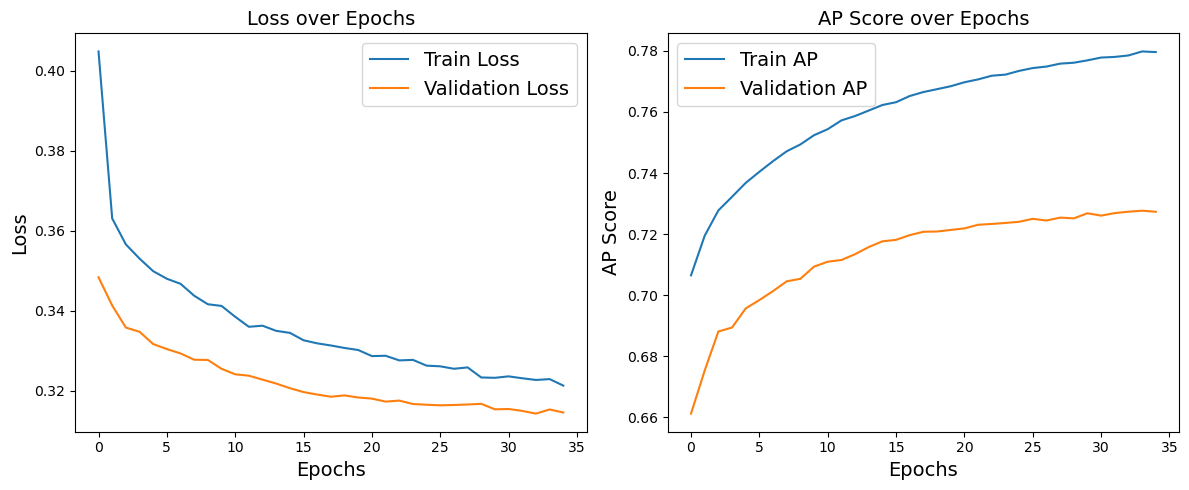

In [99]:
plt.figure(figsize=(12, 5))
# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.legend(fontsize=14)

plt.subplot(1, 2, 2)
plt.plot(history.history['train_aps'],label='Train AP')
plt.plot(history.history['val_aps'],label='Validation AP')
plt.title('AP Score over Epochs', fontsize=14)
plt.xlabel('Epochs', fontsize=14)
plt.ylabel('AP Score', fontsize=14)
plt.legend(fontsize=14)

plt.tight_layout();

In [100]:
y_proba_train = model.predict(X_train_b)#.ravel()
y_proba_val = model.predict(X_val_b)#.ravel()

print("Train-AP:      ", average_precision_score(y_train, y_proba_train))
print("Val-ROC:      ", roc_auc_score(y_val, y_proba_val))
print("Val-AP:      ", average_precision_score(y_val, y_proba_val))

y_proba_test = model.predict(X_test_b)
print("Test-ROC-AUC:  ", roc_auc_score(y_test, y_proba_test))   
print("Test-AP:      ", average_precision_score(y_test, y_proba_test))

######finding threshold on validation set#############################
def score(probabilite, seuil):
    return (probabilite >= seuil).astype('int')

thresholds = np.arange(0, 1, 0.001)

scores = [f1_score(y_val, score(y_proba_val, t)) for t in thresholds]

ix = np.argmax(scores)

final_thres = thresholds[ix]
    
f1=scores[ix]

print("Threshold ValidationSet:", final_thres)
print("F1 (Validation):", scores[ix])


#########applying threshold to test set######################
preds_test = score(y_proba_test, final_thres)

print("Test-F1:", f1_score(y_test, preds_test))

2356/2356 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
544/544 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Train-AP:       0.7798101773455013
Val-ROC:       0.8912118212741034
Val-AP:       0.7276821180636743
725/725 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Test-ROC-AUC:   0.8847466186699849
Test-AP:       0.7349062344648537
Threshold ValidationSet: 0.273
F1 (Validation): 0.6582946125831973
Test-F1: 0.6583830073041727
